# Classification d'images par réseaux de neurones convolutifs (CNN)
## Empreintes matérielles à partir de spectrogrammes STFT de signaux de tension

## 1. Présentation du problème et du jeu de données

**Problème.** Des cartes électroniques (« embedded boards ») nominalement identiques présentent de très
petites différences électriques liées à la fabrication (tolérances des composants, comportement de
commutation, horloge, etc.). Ces différences laissent une signature dans le signal de tension de sortie.
L'objectif est d'**identifier l'appareil source** à partir de cette signature : c'est de
l'*empreinte matérielle* (hardware fingerprinting), utile pour l'authentification de dispositifs embarqués
et la sécurité de la couche physique.

**Tâche.** Classification multiclasse supervisée : image de spectrogramme → classe d'appareil.

**Démarche.** On entraîne un **CNN de référence** simple, puis un **CNN amélioré**, dans des conditions
strictement comparables (mêmes données, mêmes hyperparamètres d'entraînement, même graine aléatoire).


In [10]:
import os, re, random, time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score

# ------------------------- Configuration globale -------------------------
SEED = 42
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
EPOCHS = 10
LEARNING_RATE = 1e-3
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15     # le test reçoit le reste (15 %)
GAP = 5                               # images ignorées entre deux blocs (anti-fuite)
AUGMENT = False                       # augmentation légère (voir section 3)
IMG_EXTS = (".png", ".jpg", ".jpeg")
OUT_DIR = "/kaggle/working"
os.makedirs(OUT_DIR, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow :", tf.__version__)
print("GPU        :", tf.config.list_physical_devices("GPU"))

def find_dataset_root(base="/kaggle/input"):
    # Premier dossier (le moins profond) contenant au moins 2 sous-dossiers d'images
    for root, dirs, _ in os.walk(base):
        class_dirs = [d for d in dirs
                      if any(f.lower().endswith(IMG_EXTS) for f in os.listdir(os.path.join(root, d)))]
        if len(class_dirs) >= 2:
            return root
    raise FileNotFoundError("Aucun dossier de classes trouvé sous /kaggle/input")

DATA_DIR = find_dataset_root()
print("DATA_DIR   :", DATA_DIR)

TensorFlow : 2.20.0
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
DATA_DIR   : /kaggle/input/datasets/hasanaliarif/spectrograms-for-hardware-fingerprinting/DeviceSpecific_Dataset


## 2. Exploration des données
Nombre d'images, nombre de classes, répartition, dimensions/format, et exemples.

Nombre de classes : 9
Nombre total d'images : 81000
0    9000
1    9000
2    9000
3    9000
4    9000
5    9000
6    9000
7    9000
8    9000


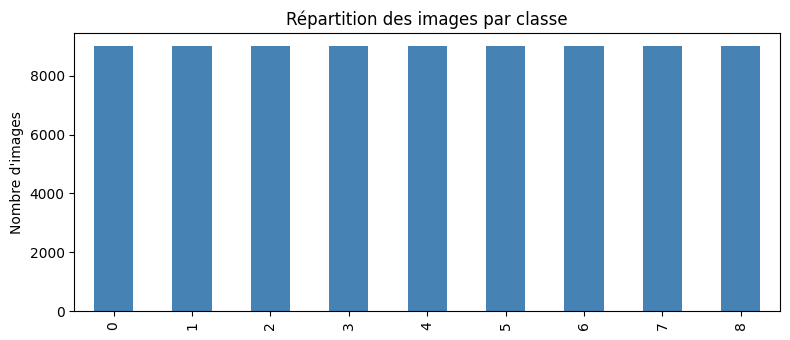

Classes équilibrées : True


In [11]:
def natural_key(s):
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r"(\d+)", s)]

class_names = sorted(d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d)))
class_to_idx = {c: i for i, c in enumerate(class_names)}
NUM_CLASSES = len(class_names)

all_paths = {}
for c in class_names:
    folder = os.path.join(DATA_DIR, c)
    files = sorted((f for f in os.listdir(folder) if f.lower().endswith(IMG_EXTS)), key=natural_key)
    all_paths[c] = [os.path.join(folder, f) for f in files]

counts = pd.Series({c: len(p) for c, p in all_paths.items()}, name="nb_images")
print(f"Nombre de classes : {NUM_CLASSES}")
print(f"Nombre total d'images : {counts.sum()}")
print(counts.to_string())

ax = counts.plot(kind="bar", figsize=(8, 3.5), color="steelblue")
ax.set_title("Répartition des images par classe"); ax.set_ylabel("Nombre d'images")
plt.tight_layout(); plt.show()
print("Classes équilibrées :", counts.nunique() == 1)

In [12]:
# Dimensions, mode couleur et format : échantillon de 200 images par classe
rng = random.Random(SEED)
size_c, mode_c, fmt_c = Counter(), Counter(), Counter()
for c, paths in all_paths.items():
    for p in rng.sample(paths, min(200, len(paths))):
        with Image.open(p) as im:
            size_c[im.size] += 1; mode_c[im.mode] += 1; fmt_c[im.format] += 1

print("Dimensions (largeur, hauteur) :", dict(size_c))
print("Modes couleur                 :", dict(mode_c))
print("Formats de fichier            :", dict(fmt_c))

Dimensions (largeur, hauteur) : {(775, 462): 1800}
Modes couleur                 : {'RGB': 1800}
Formats de fichier            : {'JPEG': 1800}


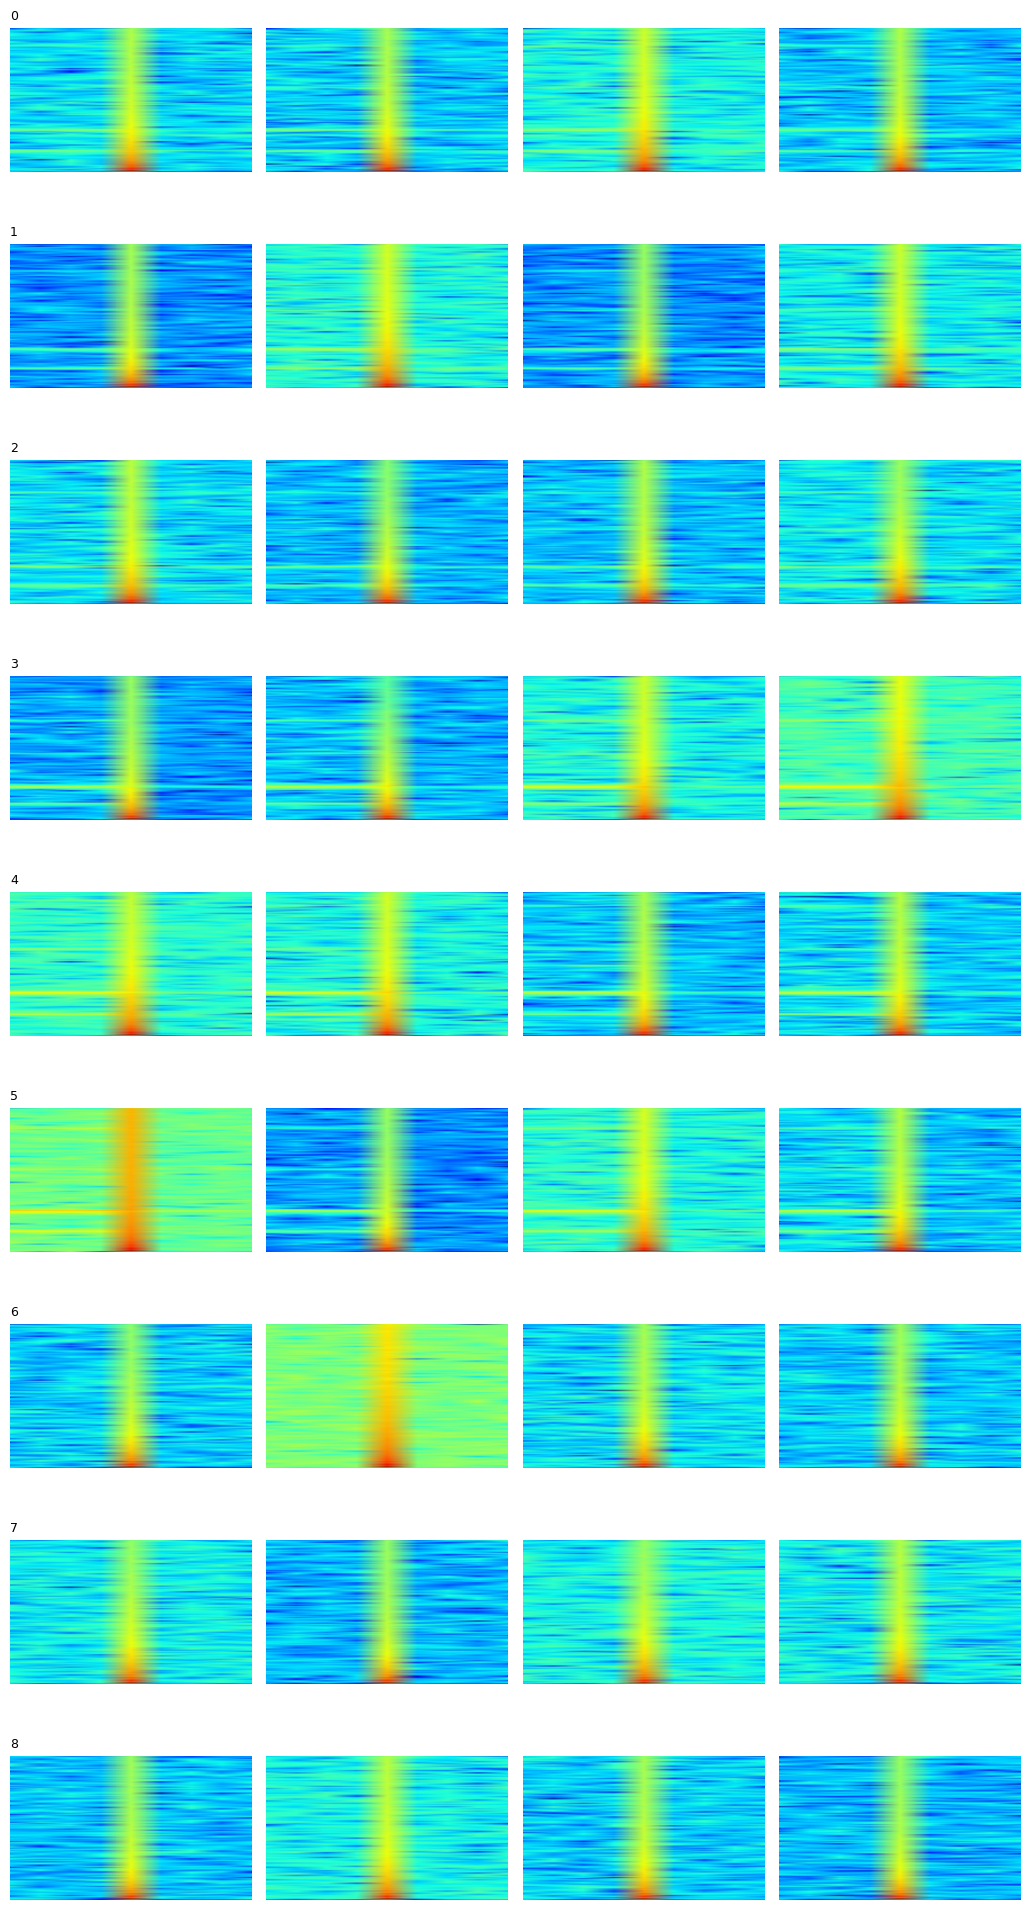

In [13]:
# Exemples : 4 spectrogrammes par classe
N_EX = 4
fig, axes = plt.subplots(NUM_CLASSES, N_EX, figsize=(2.6 * N_EX, 2.2 * NUM_CLASSES))
for i, c in enumerate(class_names):
    for j, p in enumerate(rng.sample(all_paths[c], N_EX)):
        axes[i, j].imshow(Image.open(p).convert("RGB"))
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_title(c, loc="left", fontsize=9)
plt.tight_layout(); plt.show()

In [9]:
def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    return tf.cast(img, tf.float32) / 255.0, label
 
def make_ds(split, shuffle=False):
    paths, labels = splits[split]
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
 
train_ds, val_ds, test_ds = make_ds("train", True), make_ds("val"), make_ds("test")

## 3. Prétraitement

- **Redimensionnement** : toutes les images sont ramenées à `IMG_SIZE`.
- **Normalisation** : valeurs de pixels mises à l'échelle dans [0, 1].
- **Séparation entraînement / validation / test (70 / 15 / 15)** : pour chaque classe, les fichiers sont triés
  par nom puis découpés en **blocs contigus** séparés par un intervalle de `GAP` images, afin d'éviter que des
  cycles voisins quasi identiques se retrouvent à la fois dans l'entraînement et le test.
  (Hypothèse : l'ordre des noms de fichiers reflète l'ordre d'acquisition.)
- **Augmentation** : désactivée par défaut. Les axes d'un spectrogramme (temps, fréquence) portent du sens :
  retournements et rotations détruiraient la signature. Si `AUGMENT = True`, seules des perturbations légères
  (bruit, contraste) sont appliquées, à l'entraînement uniquement et **aux deux modèles**.

In [14]:
splits = {"train": ([], []), "val": ([], []), "test": ([], [])}
rows = []
for c in class_names:
    paths = all_paths[c]
    n = len(paths)
    n_train, n_val = int(n * TRAIN_FRAC), int(n * VAL_FRAC)
    blocks = {
        "train": paths[:n_train],
        "val":   paths[n_train + GAP : n_train + GAP + n_val],
        "test":  paths[n_train + n_val + 2 * GAP :],
    }
    for s, plist in blocks.items():
        splits[s][0].extend(plist)
        splits[s][1].extend([class_to_idx[c]] * len(plist))
    rows.append({"classe": c, "total": n, **{s: len(v) for s, v in blocks.items()}})

split_df = pd.DataFrame(rows).set_index("classe")
print(split_df.to_string())
print("\nTotaux :", {s: len(v[0]) for s, v in splits.items()})

        total  train   val  test
classe                          
0        9000   6300  1350  1340
1        9000   6300  1350  1340
2        9000   6300  1350  1340
3        9000   6300  1350  1340
4        9000   6300  1350  1340
5        9000   6300  1350  1340
6        9000   6300  1350  1340
7        9000   6300  1350  1340
8        9000   6300  1350  1340

Totaux : {'train': 56700, 'val': 12150, 'test': 12060}


In [15]:
augment_layers = tf.keras.Sequential([layers.RandomContrast(0.1), layers.GaussianNoise(0.02)])

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    return tf.cast(img, tf.float32) / 255.0, label          # normalisation [0, 1]

def augment(img, label):
    return tf.clip_by_value(augment_layers(img, training=True), 0.0, 1.0), label

def make_ds(split, shuffle=False, use_aug=False):
    paths, labels = splits[split]
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    if use_aug:
        ds = ds.map(augment, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# Les deux modèles utiliseront exactement ces mêmes jeux de données
train_ds = make_ds("train", shuffle=True, use_aug=AUGMENT)
val_ds   = make_ds("val")
test_ds  = make_ds("test")        # non mélangé : l'ordre correspond à splits["test"][1]
print("Jeux de données prêts.")

I0000 00:00:1794833431.215265      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1794833431.223365      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Jeux de données prêts.


## 4. CNN basique de référence
Architecture volontairement simple : 2 blocs convolution + max-pooling, puis une couche dense.
Elle sert de point de comparaison.

In [16]:
def build_baseline():
    inp = layers.Input(shape=(*IMG_SIZE, 3))
    x = layers.Conv2D(16, 3, activation="relu")(inp)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(32, 3, activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dense(64, activation="relu")(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return models.Model(inp, out, name="cnn_baseline")

tf.random.set_seed(SEED)
baseline = build_baseline()
baseline.summary()

Model: "cnn_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 28800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,843,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │           585 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,848,937 (7.05 MB)

 Trainable params: 1,848,937 (7.05 MB)

 Non-trainable params: 0 (0.00 B)

## 5. CNN amélioré
Améliorations par rapport à la référence, chacune ayant un rôle précis :
- **Blocs plus profonds** (2 convolutions par bloc, 32 → 256 filtres) : extraction de caractéristiques plus riches.
- **Batch Normalization** : entraînement plus stable et plus rapide.
- **Dropout** (0,25 dans les blocs, 0,5 avant la sortie) : régularisation contre le surapprentissage.
- **Global Average Pooling** à la place de `Flatten` : beaucoup moins de paramètres dans la partie dense.

In [17]:
def conv_block(x, filters):
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
    x = layers.MaxPooling2D()(x)
    return layers.Dropout(0.25)(x)

def build_improved():
    inp = layers.Input(shape=(*IMG_SIZE, 3))
    x = inp
    for f in (32, 64, 128, 256):
        x = conv_block(x, f)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return models.Model(inp, out, name="cnn_improved")

tf.random.set_seed(SEED)
improved = build_improved()
improved.summary()

Model: "cnn_improved"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 64, 64, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 1,209,193 (4.61 MB)

 Trainable params: 1,207,273 (4.61 MB)

 Non-trainable params: 1,920 (7.50 KB)

## 6. Entraînement des deux modèles dans des conditions comparables
Mêmes données, même optimiseur (Adam, pas `LEARNING_RATE`), même taille de lot, même nombre maximal
d'époques, mêmes callbacks (arrêt anticipé, réduction du pas d'apprentissage) et même graine.
Le jeu de test n'est **jamais** utilisé pendant l'entraînement.

In [22]:
def train_model(model, name):
    model.compile(optimizer=optimizers.Adam(LEARNING_RATE),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    cbs = [
        callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
        callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6),
        callbacks.ModelCheckpoint(os.path.join(OUT_DIR, f"{name}.keras"),
                                  monitor="val_loss", save_best_only=True),
    ]
    t0 = time.time()
    h = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=cbs, verbose=2)
    return h.history, time.time() - t0

print(">>> Entraînement du CNN de référence")
hist_base, time_base = train_model(baseline, "cnn_baseline")
print(f"Durée : {time_base/60:.1f} min")

>>> Entraînement du CNN de référence
Epoch 1/10
1772/1772 - 79s - 45ms/step - accuracy: 0.9268 - loss: 0.1647 - val_accuracy: 0.8427 - val_loss: 0.3529 - learning_rate: 0.0010
Epoch 2/10
1772/1772 - 75s - 42ms/step - accuracy: 0.9359 - loss: 0.1465 - val_accuracy: 0.8302 - val_loss: 0.4338 - learning_rate: 0.0010
Epoch 3/10
1772/1772 - 75s - 42ms/step - accuracy: 0.9436 - loss: 0.1300 - val_accuracy: 0.8284 - val_loss: 0.5081 - learning_rate: 0.0010
Epoch 4/10
1772/1772 - 75s - 42ms/step - accuracy: 0.9635 - loss: 0.0914 - val_accuracy: 0.8265 - val_loss: 0.5795 - learning_rate: 5.0000e-04
Epoch 5/10
1772/1772 - 75s - 42ms/step - accuracy: 0.9698 - loss: 0.0765 - val_accuracy: 0.8294 - val_loss: 0.6090 - learning_rate: 5.0000e-04
Epoch 6/10
1772/1772 - 76s - 43ms/step - accuracy: 0.9805 - loss: 0.0554 - val_accuracy: 0.8296 - val_loss: 0.6904 - learning_rate: 2.5000e-04
Durée : 7.6 min


In [23]:
print(">>> Entraînement du CNN amélioré")
hist_impr, time_impr = train_model(improved, "cnn_improved")
print(f"Durée : {time_impr/60:.1f} min")

>>> Entraînement du CNN amélioré
Epoch 1/10


2026-11-16 14:30:01.395766: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-16 14:30:01.549304: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-16 14:30:02.864659: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-16 14:30:03.146961: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-16 14:31:51.803287: E external/local_xla/xla/stream_

1772/1772 - 144s - 81ms/step - accuracy: 0.8936 - loss: 0.2666 - val_accuracy: 0.9588 - val_loss: 0.1100 - learning_rate: 0.0010
Epoch 2/10
1772/1772 - 111s - 63ms/step - accuracy: 0.9592 - loss: 0.1113 - val_accuracy: 0.9642 - val_loss: 0.1067 - learning_rate: 0.0010
Epoch 3/10
1772/1772 - 111s - 63ms/step - accuracy: 0.9667 - loss: 0.0960 - val_accuracy: 0.9723 - val_loss: 0.0941 - learning_rate: 0.0010
Epoch 4/10
1772/1772 - 111s - 63ms/step - accuracy: 0.9707 - loss: 0.0872 - val_accuracy: 0.9730 - val_loss: 0.0880 - learning_rate: 0.0010
Epoch 5/10
1772/1772 - 111s - 62ms/step - accuracy: 0.9735 - loss: 0.0835 - val_accuracy: 0.9456 - val_loss: 0.1431 - learning_rate: 0.0010
Epoch 6/10
1772/1772 - 111s - 62ms/step - accuracy: 0.9746 - loss: 0.0793 - val_accuracy: 0.9601 - val_loss: 0.1186 - learning_rate: 0.0010
Epoch 7/10
1772/1772 - 111s - 62ms/step - accuracy: 0.9811 - loss: 0.0672 - val_accuracy: 0.9544 - val_loss: 0.1240 - learning_rate: 5.0000e-04
Epoch 8/10
1772/1772 - 112s

## 7. Courbes d'apprentissage

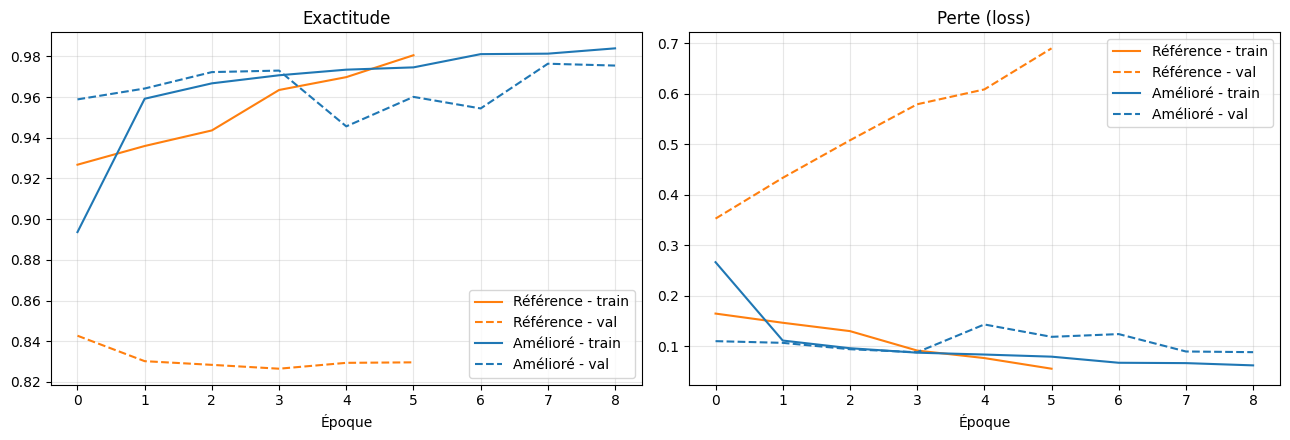

In [24]:
histories = {"Référence": hist_base, "Amélioré": hist_impr}
colors = {"Référence": "tab:orange", "Amélioré": "tab:blue"}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, key, title in zip(axes, ("accuracy", "loss"), ("Exactitude", "Perte (loss)")):
    for name, h in histories.items():
        ax.plot(h[key], color=colors[name], label=f"{name} - train")
        ax.plot(h["val_" + key], color=colors[name], linestyle="--", label=f"{name} - val")
    ax.set_title(title); ax.set_xlabel("Époque"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "courbes_apprentissage.png"), dpi=150)
plt.show()

## 8. Évaluation sur le jeu de test

In [25]:
y_true = np.array(splits["test"][1])
trained = {"Référence": baseline, "Amélioré": improved}
results, preds = {}, {}

for name, m in trained.items():
    loss, acc = m.evaluate(test_ds, verbose=0)
    y_pred = m.predict(test_ds, verbose=0).argmax(axis=1)
    preds[name] = y_pred
    results[name] = {"loss": loss, "accuracy": acc,
                     "f1_macro": f1_score(y_true, y_pred, average="macro")}
    print(f"\n===== {name} : accuracy = {acc:.4f} | loss = {loss:.4f} =====")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=4))


===== Référence : accuracy = 0.8422 | loss = 0.3507 =====
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000      1340
           1     1.0000    1.0000    1.0000      1340
           2     1.0000    1.0000    1.0000      1340
           3     1.0000    1.0000    1.0000      1340
           4     1.0000    1.0000    1.0000      1340
           5     1.0000    1.0000    1.0000      1340
           6     0.6487    0.7896    0.7122      1340
           7     0.4513    0.4015    0.4250      1340
           8     0.4353    0.3888    0.4107      1340

    accuracy                         0.8422     12060
   macro avg     0.8373    0.8422    0.8387     12060
weighted avg     0.8373    0.8422    0.8387     12060


===== Amélioré : accuracy = 0.9791 | loss = 0.0765 =====
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000      1340
           1     1.0000    1.0000    1.0000      1340
           2   

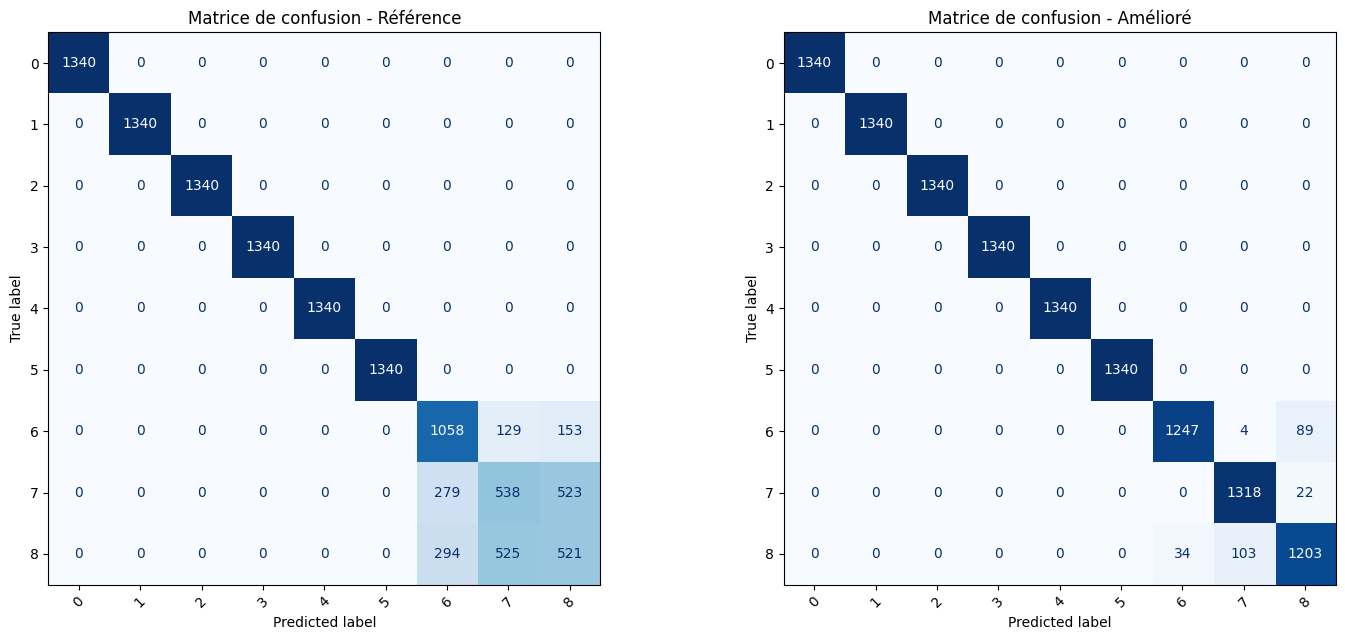

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, (name, y_pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_true, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
        ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
    ax.set_title(f"Matrice de confusion - {name}")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "matrices_confusion.png"), dpi=150)
plt.show()

## 9. Comparaison et interprétation des résultats

In [28]:
hists = {"Référence": hist_base, "Amélioré": hist_impr}
times = {"Référence": time_base, "Amélioré": time_impr}
rows = []
for name, m in trained.items():
    h = hists[name]
    rows.append({
        "Modèle": name,
        "Paramètres": m.count_params(),
        "Époques effectuées": len(h["loss"]),
        "Temps (min)": round(times[name] / 60, 1),
        "Acc. train (finale)": round(h["accuracy"][-1], 4),
        "Acc. val (meilleure)": round(max(h["val_accuracy"]), 4),
        "Acc. test": round(results[name]["accuracy"], 4),
        "F1 macro test": round(results[name]["f1_macro"], 4),
        "Loss test": round(results[name]["loss"], 4),
    })
summary = pd.DataFrame(rows).set_index("Modèle")
summary.to_csv(os.path.join(OUT_DIR, "comparaison.csv"))
summary.T

Modèle,Référence,Amélioré
Paramètres,1.848937e+06,1.209193e+06
Époques effectuées,6.000000e+00,9.000000e+00
Temps (min),7.600000e+00,1.720000e+01
Acc. train (finale),9.805000e-01,9.839000e-01
Acc. val (meilleure),8.427000e-01,9.764000e-01
Acc. test,8.422000e-01,9.791000e-01
F1 macro test,8.387000e-01,9.790000e-01
Loss test,3.507000e-01,7.650000e-02


In [29]:
# Paires de classes les plus confondues (meilleur modèle selon l'exactitude test)
best = max(results, key=lambda k: results[k]["accuracy"])
cm = confusion_matrix(y_true, preds[best]).astype(int)
np.fill_diagonal(cm, 0)
pairs = [(class_names[i], class_names[j], cm[i, j])
         for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if cm[i, j] > 0]
pairs.sort(key=lambda t: -t[2])
print(f"Modèle : {best}. Confusions les plus fréquentes (vraie classe -> prédite) :")
for t, p, n in pairs[:8]:
    print(f"  {t}  ->  {p} : {n} images")

Modèle : Amélioré. Confusions les plus fréquentes (vraie classe -> prédite) :
  8  ->  7 : 103 images
  6  ->  8 : 89 images
  8  ->  6 : 34 images
  7  ->  8 : 22 images
  6  ->  7 : 4 images
